# Initial Setting

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import threadpoolctl
import scipy.sparse as sps
import matplotlib.pyplot as plt
import optuna

from tqdm import tqdm
from xgboost import XGBRanker
from threadpoolctl import threadpool_info
from threadpoolctl import threadpool_limits
from sklearn.preprocessing import normalize

# Ignore Regex escape sequence warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)
# Ignore Cython language level warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
os.environ["OMP_NUM_THREADS"] = "1"     
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["BLIS_NUM_THREADS"] = "1"

threadpoolctl.threadpool_limits(1, "blas")

threadpool_limits(1, "openmp")  
threadpool_limits(1, "blas")    
threadpool_info()

[{'user_api': 'blas',
  'internal_api': 'mkl',
  'num_threads': 1,
  'prefix': 'libmkl_rt',
  'filepath': '/usr/local/lib/libmkl_rt.so.2',
  'version': '2025.3-Product',
  'threading_layer': 'gnu'},
 {'user_api': 'blas',
  'internal_api': 'mkl',
  'num_threads': 1,
  'prefix': 'libmkl_rt',
  'filepath': '/usr/local/lib/python3.11/dist-packages/mkl_fft.libs/libmkl_rt-089e6a60.so.2',
  'version': '2025.3-Product',
  'threading_layer': 'not specified'},
 {'user_api': 'openmp',
  'internal_api': 'openmp',
  'num_threads': 1,
  'prefix': 'libgomp',
  'filepath': '/usr/lib/x86_64-linux-gnu/libgomp.so.1.0.0',
  'version': None},
 {'user_api': 'blas',
  'internal_api': 'openblas',
  'num_threads': 1,
  'prefix': 'libscipy_openblas',
  'filepath': '/usr/local/lib/python3.11/dist-packages/scipy.libs/libscipy_openblas-68440149.so',
  'version': '0.3.28',
  'threading_layer': 'pthreads',
  'architecture': 'SkylakeX'},
 {'user_api': 'openmp',
  'internal_api': 'openmp',
  'num_threads': 1,
  'prefi

In [3]:
from kaggle_secrets import UserSecretsClient
secret_label = "RecSysToken"
token = UserSecretsClient().get_secret(secret_label)

! git clone https://{token}@github.com/JieCver1/RecSysChanllengePolimi25-26.git

fatal: destination path 'RecSysChanllengePolimi25-26' already exists and is not an empty directory.


In [4]:
%cd /kaggle/working/RecSysChanllengePolimi25-26

/kaggle/working/RecSysChanllengePolimi25-26


In [5]:
!git pull origin main

From https://github.com/JieCver1/RecSysChanllengePolimi25-26
 * branch            main       -> FETCH_HEAD
Already up to date.


In [6]:
!pip install implicit

In [7]:
from Recommenders.BaseRecommender import BaseRecommender
from implicit.als import AlternatingLeastSquares
from Recommenders.NonPersonalizedRecommender import TopPop 

from Evaluation.Evaluator import EvaluatorHoldout
from Recommenders.SLIM.SLIMElasticNetRecommender import MultiThreadSLIM_SLIMElasticNetRecommender, SLIMElasticNetRecommender
from Recommenders.GraphBased.RP3betaRecommender import RP3betaRecommender
from Recommenders.EASE_R.EASE_R_Recommender import EASE_R_Recommender
from Recommenders.KNN.ItemKNNCFRecommender import ItemKNNCFRecommender
from Recommenders.GraphBased.P3alphaRecommender import P3alphaRecommender
from Recommenders.MatrixFactorization.PureSVDRecommender import PureSVDRecommender
from Recommenders.KNN.UserKNNCFRecommender import UserKNNCFRecommender
from Recommenders.SLIM.Cython.SLIM_BPR_Cython import SLIM_BPR_Cython
from Utils.PyTorch.utils import set_reproducibility
from Data_manager.split_functions.split_train_validation_random_holdout import split_train_in_two_percentage_global_sample

set_reproducibility (42)

In [8]:
warnings.filterwarnings("ignore")

os.environ["CFLAGS"] = "-Wno-unused-function -Wno-uninitialized -Wno-cpp"
os.environ["NPY_NO_DEPRECATED_API"] = "NPY_1_7_API_VERSION"

!python run_compile_all_cython.py


run_compile_all_cython: Found 11 Cython files in 5 folders...
run_compile_all_cython: All files will be compiled using your current python environment: '/usr/bin/python3'
Compiling [1/11]: MatrixFactorization_Cython_Epoch.pyx... 
/usr/local/lib/python3.11/dist-packages/Cython/Compiler/Main.py:381: FutureWarning: Cython directive 'language_level' not set, using '3str' for now (Py3). This has changed from earlier releases! File: /kaggle/working/RecSysChanllengePolimi25-26/Recommenders/MatrixFactorization/Cython/MatrixFactorization_Cython_Epoch.pyx
  tree = Parsing.p_module(s, pxd, full_module_name)
Compiling [1/11]: MatrixFactorization_Cython_Epoch.pyx... PASS

Compiling [2/11]: MatrixFactorizationImpressions_Cython_Epoch.pyx... 
/usr/local/lib/python3.11/dist-packages/Cython/Compiler/Main.py:381: FutureWarning: Cython directive 'language_level' not set, using '3str' for now (Py3). This has changed from earlier releases! File: /kaggle/working/RecSysChanllengePolimi25-26/Recommenders/Matr

In [9]:
class ImplicitALSWrapper:
    RECOMMENDER_NAME = "IALS_Wrapper_Model"
    
    def __init__(self, URM_train):
        self.URM_train = URM_train.tocsr()
        self.n_users, self.n_items = self.URM_train.shape
        self.items_to_ignore = np.array([], dtype=np.int64)
        self.model = None

    def fit(self, factors, regularization, alpha, iterations):
        self.model = AlternatingLeastSquares(
            factors=factors,
            regularization=regularization,
            alpha=alpha,
            iterations=iterations,
            use_cg=True,
            num_threads=4,
            dtype=np.float32,
        )
        self.model.fit(self.URM_train.astype(np.float32))
        
    def get_URM_train(self):
        return self.URM_train

    def set_items_to_ignore(self, items_to_ignore):
        self.items_to_ignore = np.array(items_to_ignore, dtype=np.int64)

    def reset_items_to_ignore(self):
        self.items_to_ignore = np.array([], dtype=np.int64)
        
    def _compute_item_score(self, user_id_array, items_to_compute=None):
        # Ensure user_id_array is at least 1D for consistent matrix math
        user_id_array = np.atleast_1d(user_id_array)
        
        # Taking factors from the internal model
        user_factors = self.model.user_factors[user_id_array, :]
        
        if items_to_compute is None:
            item_factors = self.model.item_factors
        else:
            item_factors = self.model.item_factors[items_to_compute, :]
        
        # This will now ALWAYS return a 2D array of shape (len(user_id_array), n_items)
        scores = user_factors.dot(item_factors.T)
        return np.asarray(scores)

    def recommend(self, user_id_array, remove_seen_flag=True, cutoff=None,
                  remove_top_pop_flag=False, items_to_compute=None,
                  remove_custom_items_flag=False, return_scores=False):

        # FIX: Ensure we can iterate even if only one user_id is passed
        user_id_array = np.atleast_1d(user_id_array).astype(np.int64)
        
        if cutoff is None:
            cutoff = self.n_items

        # scores_batch is now guaranteed to be 2D
        scores_batch = self._compute_item_score(user_id_array)

        if remove_custom_items_flag and self.items_to_ignore.size > 0:
            scores_batch[:, self.items_to_ignore] = -np.inf

        if remove_seen_flag:
            for idx, user_id in enumerate(user_id_array):
                # This loop now works for single integers or lists
                seen_items = self.URM_train[user_id].indices
                scores_batch[idx, seen_items] = -np.inf

        recommended_items_batch_list = []

        for row_idx in range(scores_batch.shape[0]):
            user_scores = scores_batch[row_idx]
            k = min(cutoff, len(user_scores))
            # Partitioning for speed, then sorting the top K
            top_k_idx = np.argpartition(-user_scores, k - 1)[:k]
            top_k_idx = top_k_idx[np.argsort(-user_scores[top_k_idx])]
            recommended_items_batch_list.append(top_k_idx)

        if return_scores:
            return recommended_items_batch_list, scores_batch
        else:
            return recommended_items_batch_list

# Prepare dataset

In [10]:
df_train = pd.read_csv('/kaggle/input/recommender-systems-2025-challenge-polimi/data_train.csv')
df_target_users = pd.read_csv('/kaggle/input/recommender-systems-2025-challenge-polimi/data_target_users_test.csv')

In [11]:
df_train = df_train.rename(columns={'row': 'user_id', 'col': 'item_id'})
df_train['data'] = 1.0 


n_users = df_train['user_id'].max() + 1
n_items = df_train['item_id'].max() + 1

URM_all = sps.csr_matrix(
    (df_train['data'].values.astype(np.float32), 
     (df_train['user_id'].values, df_train['item_id'].values)),
    shape=(n_users, n_items)
)

print(f"URM_all Shape: {URM_all.shape}")

URM_all Shape: (27095, 6969)


In [12]:
URM_train = sps.load_npz("/kaggle/input/datasettuning/URM_train.npz")
URM_validation = sps.load_npz("/kaggle/input/datasettuning/URM_validation.npz")
URM_test = sps.load_npz("/kaggle/input/datasettuning/URM_test.npz")

In [13]:
evaluator_validation = EvaluatorHoldout(URM_validation, cutoff_list=[20])
evaluator_test = EvaluatorHoldout(URM_test, cutoff_list=[20])

target_users = df_target_users['user_id'].unique()

EvaluatorHoldout: Ignoring 463 ( 1.7%) Users that have less than 1 test interactions
EvaluatorHoldout: Ignoring 519 ( 1.9%) Users that have less than 1 test interactions


# Training

# Features setting

In [16]:
def train_base_models(URM):
    print("Training base models on URM with shape:", URM.shape)
  
    slim= MultiThreadSLIM_SLIMElasticNetRecommender(URM)
    slim.fit(l1_ratio=1.5190356919784374e-06,alpha=0.005419614628252354,topK=561,positive_only= True, workers = 4)
    
    rp3 = RP3betaRecommender(URM)
    rp3.fit(topK=40, alpha= 1.4692126186652583, beta=0.36750406285425163, normalize_similarity=True)

    easer = EASE_R_Recommender(URM)
    easer.fit(l2_norm= 423.6711768137149, topK= 649)
    
    ials = ImplicitALSWrapper(URM)
    ials.fit(factors=101, regularization=0.6025168879722137, alpha=9.465921675498674,iterations=31,)


    item_knn = ItemKNNCFRecommender(URM)
    item_knn.fit(topK=50, shrink=952, similarity='asymmetric', feature_weighting= 'TF-IDF', asymmetric_alpha= 0.024247509583039298)
    
    p3= P3alphaRecommender(URM)
    p3.fit(topK = 155, alpha = 1.3351300340675043, normalize_similarity =True)
    
    user_knn=UserKNNCFRecommender(URM)
    user_knn.fit(topK= 362, shrink=109, similarity= 'asymmetric', feature_weighting= 'TF-IDF', asymmetric_alpha= 0.3496302728900016)
    
    slimBPR= SLIM_BPR_Cython(URM)
    slimBPR.fit(topK=125, epochs= 91, lambda_i= 1.9719285330802604e-06, lambda_j= 3.4367676913044208e-06, learning_rate= 0.0821757946413263)
    
    pureSVD = PureSVDRecommender(URM)
    pureSVD.fit(num_factors= 28)
    
    top_pop = TopPop(URM)
    top_pop.fit()

    base_models = {
        "TopPop": top_pop,
        "SLIM": slim,
        "RP3": rp3,
        "EASER": easer,
        "IALS": ials,
        "ItemKNN": item_knn,
        "UserKNN": user_knn,
        "P3alpha": p3,      
        "SLIMBPR": slimBPR, 
        "PureSVD": pureSVD
    }

    return base_models

In [17]:

candidate_models = train_base_models(URM_train)


Training base models on URM with shape: (27095, 6969)


100%|█████████▉| 6968/6969 [18:30<00:00,  6.27it/s]


RP3betaRecommender: Similarity column 6969 (100.0%), 2029.74 column/sec. Elapsed time 3.43 sec
EASE_R_Recommender: Fitting model... 
EASE_R_Recommender: Fitting model... done in 19.94 sec


  0%|          | 0/31 [00:00<?, ?it/s]

Similarity column 6969 (100.0%), 2241.34 column/sec. Elapsed time 3.11 sec
P3alphaRecommender: Similarity column 6969 (100.0%), 1629.21 column/sec. Elapsed time 4.28 sec
Similarity column 27095 (100.0%), 818.64 column/sec. Elapsed time 33.10 sec
SLIM_BPR_Recommender: Automatic selection of fastest train mode. Available RAM is 29976.00 MB (93.37%) of 32103.00 MB, required is 194.27 MB. Using dense matrix.
Processed 27095 (100.0%) in 0.76 sec. BPR loss is 1.01E+01. Sample per second: 35686
SLIM_BPR_Recommender: Epoch 1 of 91. Elapsed time 0.26 sec
Processed 27095 (100.0%) in 1.07 sec. BPR loss is 1.73E+01. Sample per second: 25410
SLIM_BPR_Recommender: Epoch 2 of 91. Elapsed time 0.57 sec
Processed 27095 (100.0%) in 0.31 sec. BPR loss is 2.05E+01. Sample per second: 87548
SLIM_BPR_Recommender: Epoch 3 of 91. Elapsed time 0.81 sec
Processed 27095 (100.0%) in 0.57 sec. BPR loss is 2.28E+01. Sample per second: 47603
SLIM_BPR_Recommender: Epoch 4 of 91. Elapsed time 1.07 sec
Processed 27095 

In [18]:
print("\n" + "="*50)
print("INDIVIDUAL MODEL EVALUATION (Recall@20)")
print("="*50)

# Dictionary to store the specific results for comparison
individual_results = {}

for model_name, model_instance in candidate_models.items():
    print(f"Evaluating {model_name}...")
    
    # Run evaluation
    results_df, _ = evaluator_validation.evaluateRecommender(model_instance)
    
    # Extract Recall@20 (usually index 20 if cutoff_list was [20])
    recall_20 = results_df.loc[20]["RECALL"]
    individual_results[model_name] = recall_20
    
    print(f" > {model_name} Recall@20: {recall_20:.5f}")


INDIVIDUAL MODEL EVALUATION (Recall@20)
Evaluating TopPop...
EvaluatorHoldout: Processed 26632 (100.0%) in 12.88 sec. Users per second: 2067
 > TopPop Recall@20: 0.10645
Evaluating SLIM...
EvaluatorHoldout: Processed 26632 (100.0%) in 17.12 sec. Users per second: 1555
 > SLIM Recall@20: 0.28632
Evaluating RP3...
EvaluatorHoldout: Processed 26632 (100.0%) in 12.87 sec. Users per second: 2070
 > RP3 Recall@20: 0.24949
Evaluating EASER...
EvaluatorHoldout: Processed 26632 (100.0%) in 19.32 sec. Users per second: 1378
 > EASER Recall@20: 0.28003
Evaluating IALS...
EvaluatorHoldout: Processed 26632 (100.0%) in 13.73 sec. Users per second: 1940
 > IALS Recall@20: 0.24489
Evaluating ItemKNN...
EvaluatorHoldout: Processed 26632 (100.0%) in 13.58 sec. Users per second: 1962
 > ItemKNN Recall@20: 0.23588
Evaluating UserKNN...
EvaluatorHoldout: Processed 26632 (100.0%) in 18.87 sec. Users per second: 1411
 > UserKNN Recall@20: 0.22363
Evaluating P3alpha...
EvaluatorHoldout: Processed 26632 (100.

In [19]:
for name, model in candidate_models.items():
    try:
        recs = model.recommend([0], cutoff=5)
        print(name, "OK", len(recs[0]))
    except Exception as e:
        print(name, "ERROR:", e)


TopPop OK 5
SLIM OK 5
RP3 OK 5
EASER OK 5
IALS OK 5
ItemKNN OK 5
UserKNN OK 5
P3alpha OK 5
SLIMBPR OK 5
PureSVD OK 5


# Features setting

In [77]:
import numpy as np

def get_candidates(user_id, base_models):
    # top scores from different families (diversity)
    c = set()
    c |= set(base_models["SLIM"].recommend([user_id], cutoff=100)[0])
    c |= set(base_models["ItemKNN"].recommend([user_id], cutoff=50)[0])
    c |= set(base_models["RP3"].recommend([user_id], cutoff=80)[0])
    c |= set(base_models["IALS"].recommend([user_id], cutoff=80)[0])

    c = list(c)
    return np.array(c[:150], dtype=np.int32)



In [23]:
import random
from tqdm import tqdm


In [79]:
rows = []
users = np.unique(URM_validation.tocoo().row)

coo = URM_validation.tocoo()
true = pd.DataFrame({"u": coo.row, "i": coo.col})
true = set(zip(true.u, true.i))

for u in tqdm(users):
    cand = get_candidates(u, candidate_models)
    for i in cand:
        rows.append((u, i, (u, i) in true))

df = pd.DataFrame(rows, columns=["UserID", "ItemID", "Label"])


100%|██████████| 26632/26632 [00:55<00:00, 476.01it/s]


In [80]:
from tqdm import tqdm
import numpy as np
import pandas as pd
import scipy.sparse as sps

def build_features(df, base_models, URM):
    df_feat = df.copy()
    U, I = df.UserID.values, df.ItemID.values

    print("📌 Caching full model score matrices...")
    full_scores = {}

    # compute full item-score matrix for every model (once)
    for m in tqdm(base_models.keys(), desc="Computing model scores"):
        # ⚠ calling compute for all users at once → FASTEST
        full_scores[m] = base_models[m]._compute_item_score(np.arange(URM.shape[0]))

    print("🧬 Assign features per model...")
    for m in tqdm(base_models.keys(), desc="Assigning S/R/Z features"):
        # model score
        df_feat[f"S_{m}"] = full_scores[m][U, I]

        # ranking
        df_feat[f"R_{m}"] = df_feat.groupby("UserID")[f"S_{m}"].rank(ascending=False)

        # Z normalization
        mu  = df_feat.groupby("UserID")[f"S_{m}"].transform('mean')
        std = df_feat.groupby("UserID")[f"S_{m}"].transform('std').replace(0,1)
        df_feat[f"Z_{m}"] = (df_feat[f"S_{m}"] - mu) / std

    print("📊 Adding global statistics...")
    item_pop = np.ediff1d(sps.csc_matrix(URM).indptr)
    user_len = np.ediff1d(sps.csr_matrix(URM).indptr)

    df_feat["item_pop"] = item_pop[I]
    df_feat["log_item_pop"] = np.log1p(df_feat["item_pop"])
    df_feat["user_prof"] = user_len[U]
    df_feat["log_user_prof"] = np.log1p(df_feat["user_prof"])

    print("✨ Adding ensemble features...")
    df_feat["S_ensemble"] = (
        0.6 * df_feat["S_SLIM"] +
        0.2 * df_feat["S_IALS"] +
        0.1 * df_feat["S_RP3"] +
        0.1 * df_feat["S_ItemKNN"]
    )

    print("🏁 Features DONE:", df_feat.shape)
    return df_feat.fillna(0)


In [82]:
df_feat = build_features(df, candidate_models, URM_train)
print(df_feat.shape)
print(df_feat.Label.value_counts())


(3897520, 38)
Label
False    3728334
True      169186
Name: count, dtype: int64


In [83]:
X = df_feat.drop(columns=["UserID","ItemID","Label"])
y = df_feat["Label"].values.astype(np.float32)
groups = df_feat["UserID"].values

gss = GroupShuffleSplit(test_size=0.15, random_state=42)
tr, val = next(gss.split(X, y, groups=groups))

Xtr, ytr = X.iloc[tr], y[tr]
Xv, yv  = X.iloc[val], y[val]

_, gtr = np.unique(df_feat.iloc[tr].UserID, return_counts=True)
_, gv  = np.unique(df_feat.iloc[val].UserID, return_counts=True)

xgb = XGBRanker(
    objective="rank:pairwise",
    tree_method="gpu_hist",
    eval_metric="ndcg@20",
    learning_rate=0.03,
    max_depth=6,
    n_estimators=5000,
    subsample=0.9,
    colsample_bytree=0.8,
)

print("🚀 Training...")
xgb.fit(
    Xtr, ytr,
    group=gtr,
    eval_set=[(Xv, yv)],
    eval_group=[gv],
    early_stopping_rounds=120,
    verbose=50,
)

print("BEST SCORE:", xgb.best_score)
print("BEST ITER:", xgb.best_iteration)
best_model = xgb



🚀 Training...
[0]	validation_0-ndcg@20:0.31194
[50]	validation_0-ndcg@20:0.32033
[100]	validation_0-ndcg@20:0.32060
[150]	validation_0-ndcg@20:0.32085
[200]	validation_0-ndcg@20:0.32081
[250]	validation_0-ndcg@20:0.32084
[300]	validation_0-ndcg@20:0.32086
[350]	validation_0-ndcg@20:0.32106
[400]	validation_0-ndcg@20:0.32117
[450]	validation_0-ndcg@20:0.32095
[500]	validation_0-ndcg@20:0.32068
[530]	validation_0-ndcg@20:0.32044
BEST SCORE: 0.3213914607230991
BEST ITER: 411


In [115]:
class XGBReranker(BaseRecommender):
    def __init__(self, URM, base_models, model, feature_cols, cutoff_candidates=2000):
        super().__init__(URM)
        self.URM = URM.tocsr()
        self.base = base_models
        self.model = model
        self.feature_cols = feature_cols
        self.cutoff = cutoff_candidates
        
        self.item_pop = np.ediff1d(sps.csc_matrix(URM).indptr)
        self.user_prof = np.ediff1d(self.URM.indptr)
        self.log_item_pop = np.log1p(self.item_pop)
        self.n_users, self.n_items = URM.shape

    def _build(self, u, cand):
        df = pd.DataFrame({"UserID": u, "ItemID": cand})

        # S_* scores
        for m in self.base.keys():
            scores = self.base[m]._compute_item_score([u])[0]
            df[f"S_{m}"] = scores[cand]

        # Ranking + Z score
        for m in self.base.keys():
            col = f"S_{m}"
            df[f"R_{m}"] = df[col].rank(ascending=False)
            mu = df[col].mean()
            sd = df[col].std() or 1
            df[f"Z_{m}"] = (df[col] - mu) / sd

        # Item/User metadata
        df["item_pop"] = self.item_pop[cand]
        df["log_item_pop"] = self.log_item_pop[cand]
        df["usr_prof"] = self.user_prof[u]
        df["log_usr_prof"] = np.log1p(self.user_prof[u])

        # Score difference
        df["S_diff_SLIM_IALS"] = df["S_SLIM"] - df["S_IALS"]
        df["P_SLIM"] = df["S_SLIM"].rank(pct=True)
        df["P_IALS"] = df["S_IALS"].rank(pct=True)

        # Ensemble meta-feature
        df["S_ensemble"] = (
            0.6 * df["S_SLIM"] +
            0.2 * df["S_IALS"] +
            0.1 * df["S_RP3"] +
            0.1 * df["S_ItemKNN"]
        )

        return df[self.feature_cols].fillna(0)

    def _compute_item_score(self, users, items_to_compute=None):
        users = np.atleast_1d(users)
        scores = np.full((len(users), self.n_items), -np.inf, dtype=np.float32)

        for idx, u in enumerate(users):
            # ------------- FIX HERE ------------
            cand = get_candidates(u, self.base)
            # -----------------------------------

            if len(cand) == 0:
                continue
            
            X_u = self._build(u, cand)
            preds = self.model.predict(X_u)
            scores[idx, cand] = preds

        return scores

    def recommend(self, user_id_array, cutoff=20, remove_seen_flag=True, return_scores=False, **kwargs):
        user_id_array = np.atleast_1d(user_id_array)
        scores = self._compute_item_score(user_id_array)

        if remove_seen_flag:
            for i, u in enumerate(user_id_array):
                seen = self.URM[u].indices
                scores[i, seen] = -np.inf

        recs = []
        for row in scores:
            top = np.argpartition(-row, cutoff)[:cutoff]
            top = top[np.argsort(-row[top])]
            recs.append(top)

        return np.array(recs), scores


In [106]:
feature_cols = X_tr.columns.tolist()


In [116]:
reranker = XGBReranker(
    URM = URM_train_final,
    base_models = candidate_models,
    model = xgb_model,
    feature_cols = feature_cols,
    cutoff_candidates = 2000
)




In [117]:
from Evaluation.Evaluator import EvaluatorHoldout

evaluator_validation = EvaluatorHoldout(URM_test, cutoff_list=[20])


EvaluatorHoldout: Ignoring 519 ( 1.9%) Users that have less than 1 test interactions


In [120]:
results_df, _ = evaluator_validation.evaluateRecommender(reranker)
print(results_df)


EvaluatorHoldout: Processed 11000 (41.4%) in 5.05 min. Users per second: 36
EvaluatorHoldout: Processed 22000 (82.8%) in 10.06 min. Users per second: 36
EvaluatorHoldout: Processed 26576 (100.0%) in 12.15 min. Users per second: 36
       PRECISION PRECISION_RECALL_MIN_DEN    RECALL       MAP MAP_MIN_DEN  \
cutoff                                                                      
20      0.111768                 0.284617  0.274771  0.037084    0.091682   

             MRR      NDCG        F1 HIT_RATE ARHR_ALL_HITS  ...  \
cutoff                                                       ...   
20      0.317896  0.209911  0.158901  0.85088      0.474107  ...   

       COVERAGE_USER COVERAGE_USER_HIT USERS_IN_GT DIVERSITY_GINI  \
cutoff                                                              
20          0.980845          0.834582    0.980845       0.073859   

       SHANNON_ENTROPY RATIO_DIVERSITY_HERFINDAHL RATIO_DIVERSITY_GINI  \
cutoff                                            

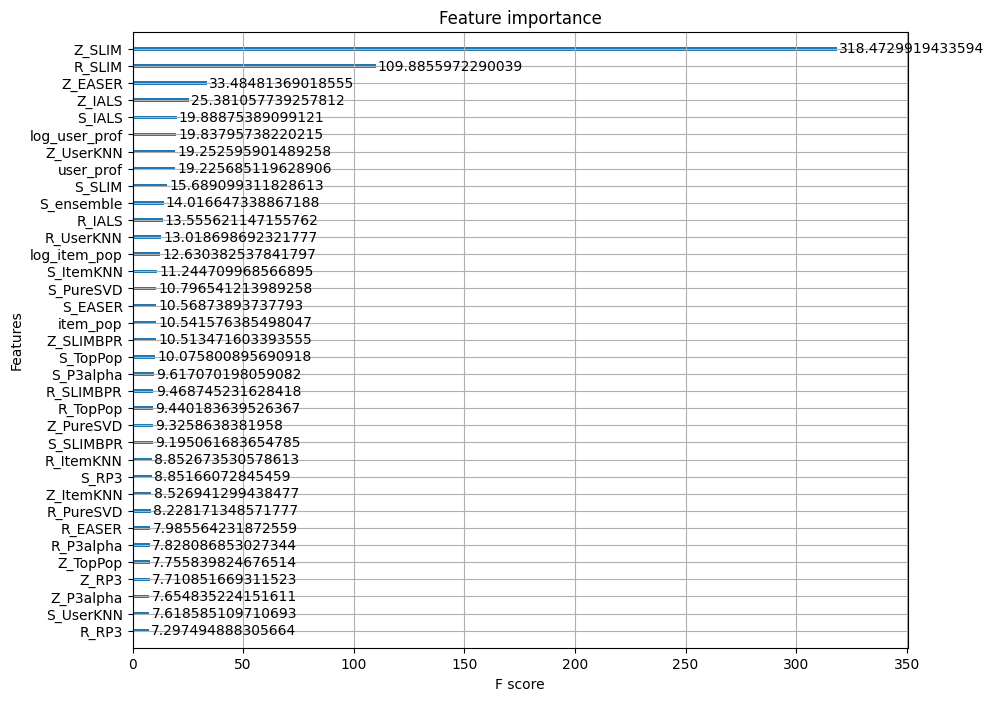

In [121]:
import matplotlib.pyplot as plt

# Plotting the Importance
fig, ax = plt.subplots(figsize=(10, 8))
# Use 'gain' because it shows which features actually contribute to the score
from xgboost import plot_importance
plot_importance(xgb, importance_type='gain', ax=ax)
plt.show()

# Final phase

In [ ]:
final_models = train_base_models(URM_all)


In [ ]:
############################################################
# FINAL SUBMISSION BUILDER
############################################################
target_users = pd.read_csv(
    "/kaggle/input/recommender-systems-2025-challenge-polimi/data_target_users_test.csv"
)["user_id"].tolist()

reranker(
    URM = URM_all,
    base_models = final_models,
    xgb_model = xgb,
    feature_cols = feature_cols,
    cutoff_candidates = 3000
)

submission = []

for u in target_users:
    if u >= URM_all.shape[0]:
        # unseen → fill with TopPop
        rec = reranker_final.top_items[:20]
    else:
        rec = reranker_final.recommend([u], cutoff=20)[0]
        if len(rec) < 20:
            # pad with popularity
            fill = [i for i in reranker_final.top_items if i not in rec]
            rec = list(rec) + fill[: 20 - len(rec)]

    submission.append({
        "user_id": int(u),
        "item_list": " ".join(map(str, rec[:20]))
    })

sub = pd.DataFrame(submission)
sub.to_csv("submission_xgb_recall20.csv", index=False)
print("💾 Saved:", "submission_xgb_recall20.csv")
print(sub.head())
